In [ ]:
import numpy as np

class PerceptronMulticapaXOR:
    def __init__(self, tasa_aprendizaje=0.5):
        # La arquitectura: 2 entradas -> 2 neuronas ocultas -> 1 salida
        # Inicializamos pesos y umbrales (sesgos) con valores aleatorios
        self.w_oculta = np.random.uniform(-1, 1, (2, 2))
        self.u_oculta = np.random.uniform(-1, 1, (1, 2))

        self.w_salida = np.random.uniform(-1, 1, (2, 1))
        self.v_salida = np.random.uniform(-1, 1, (1, 1))

        self.lr = tasa_aprendizaje

    def sigmoide(self, x):
        return 1 / (1 + np.exp(-x))

    def derivada_sigmoide(self, x):
        # Asume que 'x' ya pasó por la función sigmoide
        return x * (1 - x)

    def entrenar(self, X, t_deseada, epocas=10000):
        for epoca in range(epocas):
            # --- 1. Propagación hacia adelante (Forward) ---
            # Capa oculta
            entrada_oculta = np.dot(X, self.w_oculta) + self.u_oculta
            salida_oculta = self.sigmoide(entrada_oculta)

            # Capa de salida
            entrada_salida = np.dot(salida_oculta, self.w_salida) + self.v_salida
            y_pred = self.sigmoide(entrada_salida)

            # --- 2. Cálculo del Error ---
            error = t_deseada - y_pred

            # --- 3. Retropropagación (Backpropagation) ---
            # Gradiente de la capa de salida
            d_salida = error * self.derivada_sigmoide(y_pred)

            # Gradiente de la capa oculta
            error_oculta = d_salida.dot(self.w_salida.T)
            d_oculta = error_oculta * self.derivada_sigmoide(salida_oculta)

            # --- 4. Actualización de Pesos y Umbrales ---
            self.w_salida += salida_oculta.T.dot(d_salida) * self.lr
            self.v_salida += np.sum(d_salida, axis=0, keepdims=True) * self.lr

            self.w_oculta += X.T.dot(d_oculta) * self.lr
            self.u_oculta += np.sum(d_oculta, axis=0, keepdims=True) * self.lr

    def predecir(self, X):
        salida_oculta = self.sigmoide(np.dot(X, self.w_oculta) + self.u_oculta)
        y_pred = self.sigmoide(np.dot(salida_oculta, self.w_salida) + self.v_salida)
        # Redondeamos para obtener 0 o 1
        return np.round(y_pred)

# ==========================================
# Ejecución para la compuerta XOR
# ==========================================
if __name__ == "__main__":
    # Entradas y salidas del XOR
    X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
    t_deseada = np.array([[0], [1], [1], [0]])

    print("--- Entrenando Perceptrón Multicapa para XOR ---")
    mlp_xor = PerceptronMulticapaXOR(tasa_aprendizaje=0.5)

    # Entrenamos por 10,000 épocas
    mlp_xor.entrenar(X, t_deseada, epocas=10000)

    print("Entrenamiento finalizado. Resultados de predicción:")
    predicciones = mlp_xor.predecir(X)

    for i in range(len(X)):
        print(f"Entrada: {X[i]} -> Salida de la red: {int(predicciones[i][0])} (Deseada: {t_deseada[i][0]})")

--- Entrenando Perceptrón Multicapa para XOR ---
Entrenamiento finalizado. Resultados de predicción:
Entrada: [0 0] -> Salida de la red: 0 (Deseada: 0)
Entrada: [0 1] -> Salida de la red: 1 (Deseada: 1)
Entrada: [1 0] -> Salida de la red: 1 (Deseada: 1)
Entrada: [1 1] -> Salida de la red: 0 (Deseada: 0)


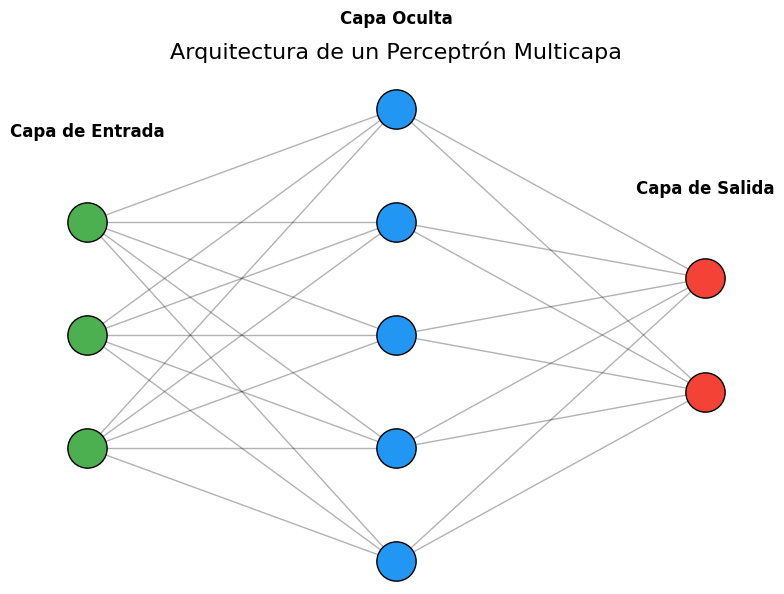

In [ ]:
import matplotlib.pyplot as plt

def graficar_arquitectura_mlp(arquitectura):
    """
    Dibuja un esquema topológico de un Perceptrón Multicapa.
    arquitectura: lista con el número de neuronas por capa.
                  Ejemplo: [3, 5, 2] -> 3 en entrada, 5 oculta, 2 salida.
    """
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.axis('off')

    distancia_capas = 2
    distancia_neuronas = 1

    posiciones_capas = []

    # Calcular posiciones de las neuronas para que queden centradas verticalmente
    for i, num_neuronas in enumerate(arquitectura):
        y_inicio = (num_neuronas - 1) * distancia_neuronas / 2
        posiciones = [(i * distancia_capas, y_inicio - j * distancia_neuronas) for j in range(num_neuronas)]
        posiciones_capas.append(posiciones)

    # Dibujar las conexiones sinápticas (líneas)
    for i in range(len(arquitectura) - 1):
        capa_actual = posiciones_capas[i]
        capa_siguiente = posiciones_capas[i + 1]

        for nodo_origen in capa_actual:
            for nodo_destino in capa_siguiente:
                ax.plot([nodo_origen[0], nodo_destino[0]],
                        [nodo_origen[1], nodo_destino[1]],
                        'k-', alpha=0.3, linewidth=1)

    # Dibujar las neuronas (nodos) y etiquetar las capas
    etiquetas = ['Capa de Entrada', 'Capa Oculta', 'Capa de Salida']
    colores = ['#4CAF50', '#2196F3', '#F44336']

    for i, capa in enumerate(posiciones_capas):
        x_coords = [p[0] for p in capa]
        y_coords = [p[1] for p in capa]
        ax.scatter(x_coords, y_coords, s=800, c=colores[i], edgecolors='black', zorder=4)

        # Etiqueta de la capa en la parte superior
        if i < len(etiquetas):
            ax.text(x_coords[0], max(y_coords) + 0.8, etiquetas[i],
                    ha='center', va='center', fontsize=12, fontweight='bold')

    plt.title("Arquitectura de un Perceptrón Multicapa", fontsize=16, pad=20)
    plt.tight_layout()
    plt.show()

# ==========================================
# Generar la gráfica del MLP
# ==========================================
if __name__ == "__main__":
    # Definimos una red con 3 entradas, 5 neuronas ocultas y 2 salidas
    capas = [3, 5, 2]
    graficar_arquitectura_mlp(capas)

Entrenando red multicapa para XOR...


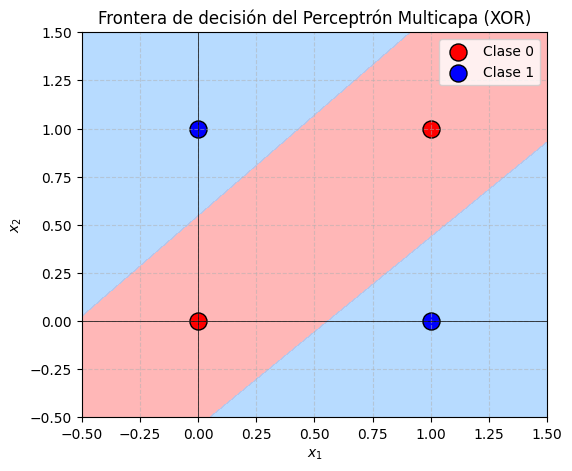

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

class PerceptronMulticapaXOR:
    def __init__(self, tasa_aprendizaje=0.5):
        # 2 entradas -> 2 neuronas ocultas -> 1 salida
        self.w_oculta = np.random.uniform(-1, 1, (2, 2))
        self.u_oculta = np.random.uniform(-1, 1, (1, 2))
        self.w_salida = np.random.uniform(-1, 1, (2, 1))
        self.v_salida = np.random.uniform(-1, 1, (1, 1))
        self.lr = tasa_aprendizaje

    def sigmoide(self, x):
        return 1 / (1 + np.exp(-x))

    def derivada_sigmoide(self, x):
        return x * (1 - x)

    def entrenar(self, X, t_deseada, epocas=10000):
        for _ in range(epocas):
            # Forward
            out_oculta = self.sigmoide(np.dot(X, self.w_oculta) + self.u_oculta)
            y_pred = self.sigmoide(np.dot(out_oculta, self.w_salida) + self.v_salida)

            # Backpropagation
            error = t_deseada - y_pred
            d_salida = error * self.derivada_sigmoide(y_pred)
            d_oculta = d_salida.dot(self.w_salida.T) * self.derivada_sigmoide(out_oculta)

            # Actualización de pesos y sesgos
            self.w_salida += out_oculta.T.dot(d_salida) * self.lr
            self.v_salida += np.sum(d_salida, axis=0, keepdims=True) * self.lr
            self.w_oculta += X.T.dot(d_oculta) * self.lr
            self.u_oculta += np.sum(d_oculta, axis=0, keepdims=True) * self.lr

    def predecir(self, X):
        out_oculta = self.sigmoide(np.dot(X, self.w_oculta) + self.u_oculta)
        return self.sigmoide(np.dot(out_oculta, self.w_salida) + self.v_salida)

def graficar_frontera_xor():
    X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
    t = np.array([[0], [1], [1], [0]])

    print("Entrenando red multicapa para XOR...")
    mlp = PerceptronMulticapaXOR(tasa_aprendizaje=0.5)
    mlp.entrenar(X, t, epocas=10000)

    # Crear una malla de puntos en el plano x1, x2
    xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 100), np.linspace(-0.5, 1.5, 100))
    malla = np.c_[xx.ravel(), yy.ravel()]

    # Predecir la salida para cada punto de la malla
    predicciones = mlp.predecir(malla)
    Z = predicciones.reshape(xx.shape)

    # Graficar las regiones de decisión
    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, Z, levels=[0, 0.5, 1], colors=['#ff9999', '#99ccff'], alpha=0.7)

    # Graficar los 4 puntos lógicos del XOR
    for i in range(len(X)):
        color = 'blue' if t[i] == 1 else 'red'
        etiqueta = f'Clase {int(t[i][0])}' if i in [0, 1] else ""
        plt.scatter(X[i, 0], X[i, 1], color=color, s=150, edgecolor='k', label=etiqueta)

    plt.title('Frontera de decisión del Perceptrón Multicapa (XOR)')
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.axhline(0, color='black', linewidth=0.5)
    plt.axvline(0, color='black', linewidth=0.5)
    plt.legend(loc='best')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

if __name__ == "__main__":
    graficar_frontera_xor()

In [ ]:
import numpy as np
import time

inicio = time.time()

# --- 1. Funciones matemáticas ---
def sigmoidea_bipolar(v):
    return (1 / (1 + np.exp(-2 * v))) - 0.5

def derivada_sigmoidea_bipolar(y):
    return 2 * (y + 0.5) * (0.5 - y)

# --- 2. Parámetros Iniciales e Inputs ---
X = np.array([[-0.5, -0.5],
              [-0.5,  0.5],
              [ 0.5, -0.5],
              [ 0.5,  0.5]])

T = np.array([[-0.5],
              [ 0.5],
              [ 0.5],
              [-0.5]])

np.random.seed(42)
# Usamos 4 neuronas ocultas para evitar que se atasque en mínimos locales
neuronas_ocultas = 4

W_oculta = np.random.uniform(-1.0, 1.0, (2, neuronas_ocultas))
U_oculta = np.random.uniform(-1.0, 1.0, (1, neuronas_ocultas))

W_salida = np.random.uniform(-1.0, 1.0, (neuronas_ocultas, 1))
V_salida = np.random.uniform(-1.0, 1.0, (1, 1))

alfa = 0.8
error_objetivo = 0.0002
max_ciclos = 50000 # Seguro contra bucles infinitos

# --- 3. Bucle de Entrenamiento Vectorizado ---
ciclo = 0
error_medio = 1.0

while error_medio > error_objetivo and ciclo < max_ciclos:
    # --- PROPAGACIÓN HACIA ADELANTE (Los 4 patrones a la vez) ---
    v_oculta = np.dot(X, W_oculta) + U_oculta
    b = sigmoidea_bipolar(v_oculta)

    v_salida = np.dot(b, W_salida) + V_salida
    y = sigmoidea_bipolar(v_salida)

    # Evaluar el error cuadrático medio
    error_medio = np.mean(0.5 * (T - y)**2)

    # --- RETROPROPAGACIÓN ---
    delta_salida = (T - y) * derivada_sigmoidea_bipolar(y)
    delta_oculta = np.dot(delta_salida, W_salida.T) * derivada_sigmoidea_bipolar(b)

    # Actualización de Pesos y Umbrales
    W_salida += alfa * np.dot(b.T, delta_salida)
    V_salida += alfa * np.sum(delta_salida, axis=0, keepdims=True)

    W_oculta += alfa * np.dot(X.T, delta_oculta)
    U_oculta += alfa * np.sum(delta_oculta, axis=0, keepdims=True)

    ciclo += 1

tiempo_total = time.time() - inicio
print(f"✅ Entrenamiento completado en {ciclo} ciclos ({tiempo_total:.4f} segundos).")
print(f"📉 Error Cuadrático Medio Final: {error_medio:.6f}")

# Probar la red entrenada
print("\n--- Resultados de la predicción XOR ---")
for i in range(len(X)):
    print(f"Entrada: {X[i]} | Salida deseada: {T[i][0]:4.1f} | Salida red: {y[i][0]:.6f}")

✅ Entrenamiento completado en 671 ciclos (0.0770 segundos).
📉 Error Cuadrático Medio Final: 0.000200

--- Resultados de la predicción XOR ---
Entrada: [-0.5 -0.5] | Salida deseada: -0.5 | Salida red: -0.480116
Entrada: [-0.5  0.5] | Salida deseada:  0.5 | Salida red: 0.480428
Entrada: [ 0.5 -0.5] | Salida deseada:  0.5 | Salida red: 0.479310
Entrada: [0.5 0.5] | Salida deseada: -0.5 | Salida red: -0.480184
